In [1]:
from itertools import product
import pickle
import json
import h5py
from tqdm import tqdm, trange

import numpy as np
from numpy.linalg import eigh
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Ellipse
from corner import corner as corner_plot

from scipy import special, stats
from scipy.stats import gaussian_kde, chi2
from scipy.interpolate import RegularGridInterpolator

import os

from local_utils import delaunaytor
from popsummary.popresult import PopulationResult
from astropy.cosmology import Planck15
from astropy import units as u


plt.style.use("tableau-colorblind10")
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 14
plt.rcParams["text.usetex"] = True

# GW events

## From Alex file

In [2]:
parameter_keys_0 = ["m1", "z", "q", "chi1", "chi2", "tilt1", "tilt2"]

data_file = np.load("./alex_samples/lvc_data_lvc_samples_full.npz")
observed_events_0 = np.vstack([data_file[key + "s"] for key in parameter_keys_0]).T
num_events_0 = data_file["nevents"][0]
num_samples_0 = data_file["nsamples"][0]
event_priors_0 = data_file["priors"]
print(
        f"Running with {num_events_0} events × {num_samples_0} samples = {num_events_0*num_samples_0} total samples"
    )

event_barycenters_0 = observed_events_0.reshape(
    (num_events_0, num_samples_0, observed_events_0.shape[-1])
).mean(axis=1)

Running with 69 events × 4278 samples = 295182 total samples


## From gwax

In [3]:
parameter_keys_1 = ["m1", "z", "q", "chi1", "chi2", "cos_tilt_1", "cos_tilt_2"]

data_file = np.load("./gwax_samples/gwtc3_samples.npz")
observed_events_1 = np.vstack([data_file[key + "s"] for key in parameter_keys_1]).T
num_events_1 = data_file["nevents"]
num_samples_1 = data_file["nsamples"]
event_priors_1 = data_file["priors"]
print(
        f"Running with {num_events_1} events × {num_samples_1} samples = {num_events_1*num_samples_1} total samples"
    )

event_barycenters_1 = observed_events_1.reshape(
    (num_events_1, num_samples_1, observed_events_1.shape[-1])
).mean(axis=1)

Running with 69 events × 3194 samples = 220386 total samples


## Look at event barycenters

Number of events from Alex file with q~0.2: 1
Number of events from gwax file with q~0.2: 1


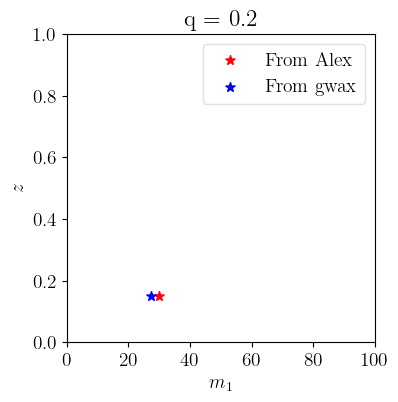

Number of events from Alex file with q~0.5: 69
Number of events from gwax file with q~0.5: 69


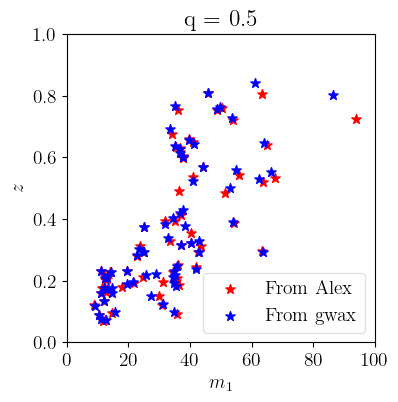

Number of events from Alex file with q~0.8: 69
Number of events from gwax file with q~0.8: 69


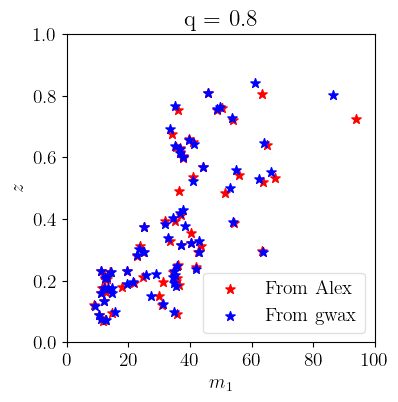

In [4]:

for qeval in [0.2, 0.5, 0.8]:
    fig, ax = plt.subplots(figsize=(4,4))
    ax.set(title=f"q = {qeval}")

    events_at_q_0 = np.abs(event_barycenters_0[:,2]-qeval) /qeval < 1
    print(f"Number of events from Alex file with q~{qeval}: {np.sum(events_at_q_0)}")
    ax.scatter(event_barycenters_0[events_at_q_0,0], event_barycenters_0[events_at_q_0,1],
               c='red', marker='*', s=7**2, zorder=2,
               label='From Alex',
              )

    events_at_q_1 = np.abs(event_barycenters_1[:,2]-qeval) /qeval < 1
    print(f"Number of events from gwax file with q~{qeval}: {np.sum(events_at_q_1)}")
    ax.scatter(event_barycenters_1[events_at_q_1,0], event_barycenters_1[events_at_q_1,1],
               c='blue', marker='*', s=7**2, zorder=2,
               label='From gwax',
              )

    # injections_at_q = np.abs(detected_injections[:,2]-q_grid[qeval_ind]) < 0.01
    # ax.scatter(detected_injections[injections_at_q,0], detected_injections[injections_at_q,1],
    #            c='r', marker='d', s=4**2, zorder=1,
    #            label='Detected injections',
    #           )
    ax.set_xlabel('$m_1$')
    ax.set_xlim(0,100)
    ax.set_ylabel('$z$')
    ax.set_ylim(0., 1.)
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
    
    plt.show()
    plt.close()

Number of events from Alex file with z~0.2: 44
Number of events from gwax file with z~0.2: 43


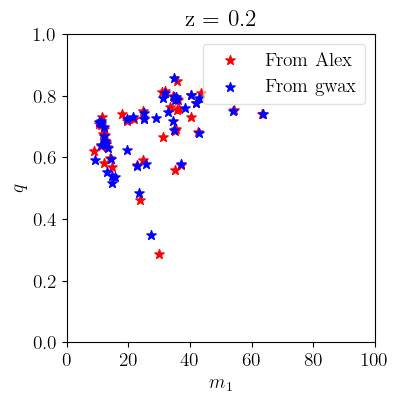

Number of events from Alex file with z~0.5: 68
Number of events from gwax file with z~0.5: 68


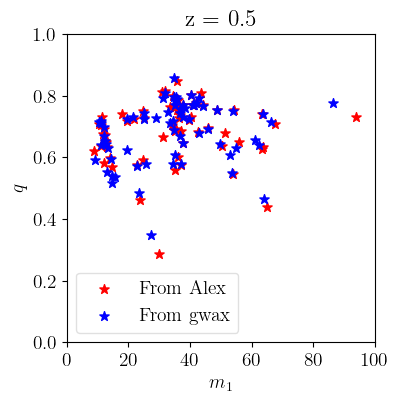

Number of events from Alex file with z~0.8: 69
Number of events from gwax file with z~0.8: 69


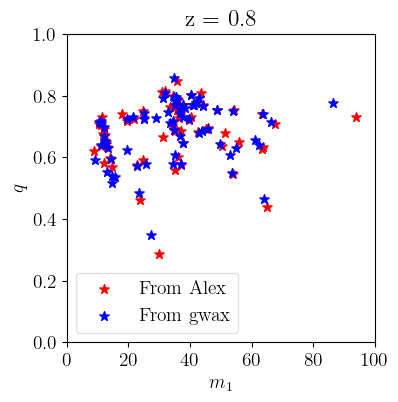

In [5]:

for zeval in [0.2, 0.5, 0.8]:
    fig, ax = plt.subplots(figsize=(4,4))
    ax.set(title=f"z = {zeval}")

    events_at_z_0 = np.abs(event_barycenters_0[:,1]-zeval) /zeval < 1
    print(f"Number of events from Alex file with z~{zeval}: {np.sum(events_at_z_0)}")
    ax.scatter(event_barycenters_0[events_at_z_0,0], event_barycenters_0[events_at_z_0,2],
               c='red', marker='*', s=7**2, zorder=2,
               label='From Alex',
              )

    events_at_z_1 = np.abs(event_barycenters_1[:,1]-zeval) /zeval < 1
    print(f"Number of events from gwax file with z~{zeval}: {np.sum(events_at_z_1)}")
    ax.scatter(event_barycenters_1[events_at_z_1,0], event_barycenters_1[events_at_z_1,2],
               c='blue', marker='*', s=7**2, zorder=2,
               label='From gwax',
              )

    # injections_at_q = np.abs(detected_injections[:,2]-q_grid[qeval_ind]) < 0.01
    # ax.scatter(detected_injections[injections_at_q,0], detected_injections[injections_at_q,1],
    #            c='r', marker='d', s=4**2, zorder=1,
    #            label='Detected injections',
    #           )
    ax.set_xlabel('$m_1$')
    ax.set_xlim(0,100)
    ax.set_ylabel('$q$')
    ax.set_ylim(0., 1.)
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
    
    plt.show()
    plt.close()

## Look at posterior distributions

In [6]:
first_event_0 = observed_events_0[:num_samples_0,:]
first_event_1 = observed_events_1[:num_samples_1,:]

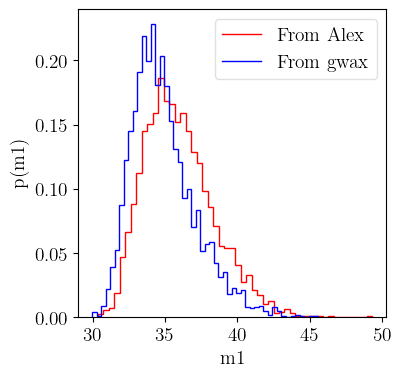

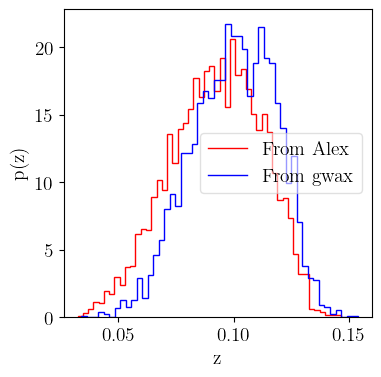

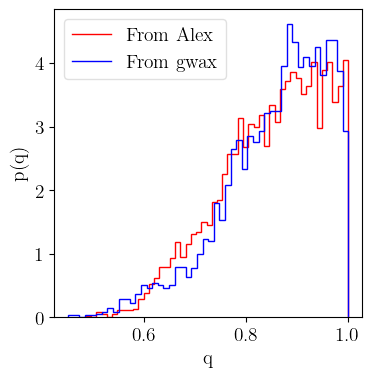

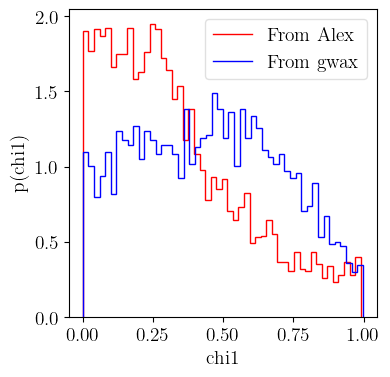

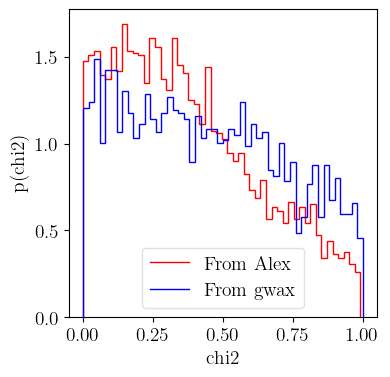

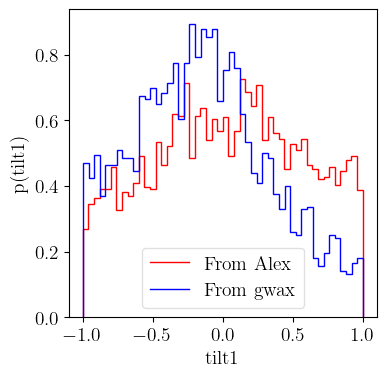

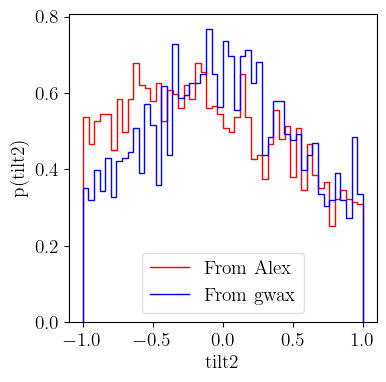

In [7]:
nbins=50

for k,key in enumerate(parameter_keys_0):
    
    fig, ax = plt.subplots(1, 1, figsize=(4,4))

    hist0, bins0 = np.histogram(first_event_0[:,k], bins=nbins, density=True)
    hist1, bins1 = np.histogram(first_event_1[:,k], bins=nbins, density=True)
    
    ax.stairs(hist0, bins0, color='r', label='From Alex')
    ax.stairs(hist1, bins1, color='blue', label='From gwax')
    
    ax.set_xlabel(key)
    ax.set_ylabel(f"p({key})")
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
    
    plt.show()

In [8]:
second_event_0 = observed_events_0[num_samples_0:2*num_samples_0,:]
second_event_1 = observed_events_1[num_samples_1:2*num_samples_1,:]

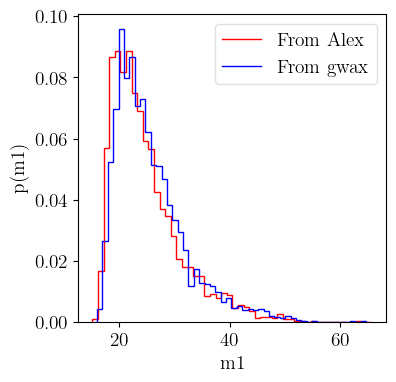

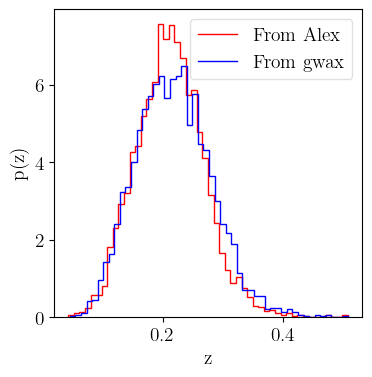

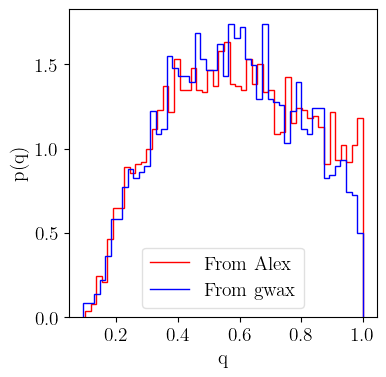

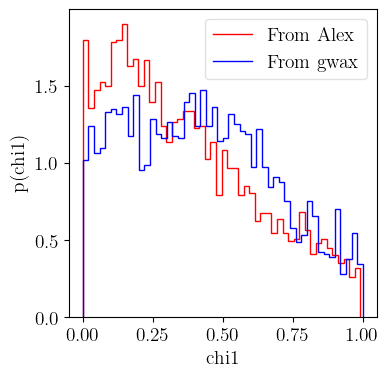

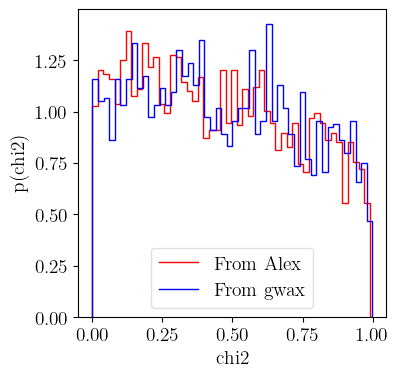

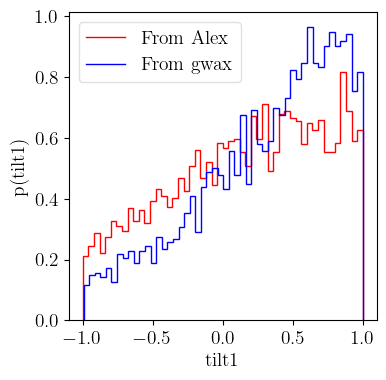

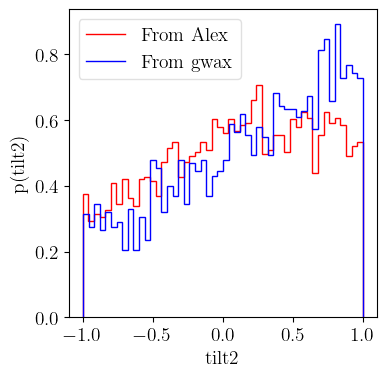

In [9]:
nbins=50

for k,key in enumerate(parameter_keys_0):
    
    fig, ax = plt.subplots(1, 1, figsize=(4,4))

    hist0, bins0 = np.histogram(second_event_0[:,k], bins=nbins, density=True)
    hist1, bins1 = np.histogram(second_event_1[:,k], bins=nbins, density=True)
    
    ax.stairs(hist0, bins0, color='r', label='From Alex')
    ax.stairs(hist1, bins1, color='blue', label='From gwax')
    
    ax.set_xlabel(key)
    ax.set_ylabel(f"p({key})")
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
    
    plt.show()

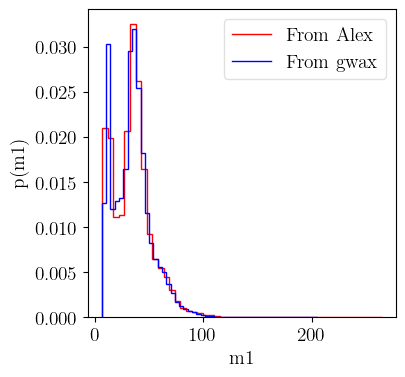

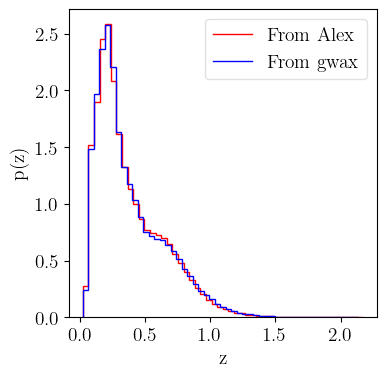

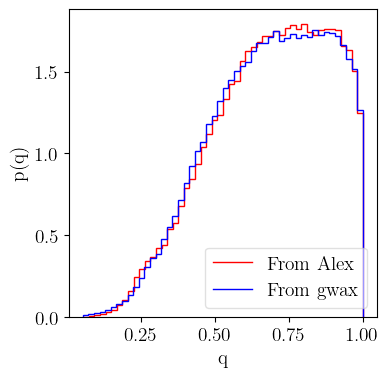

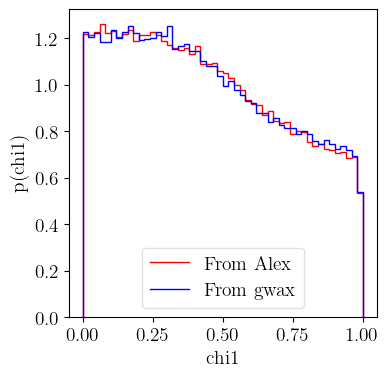

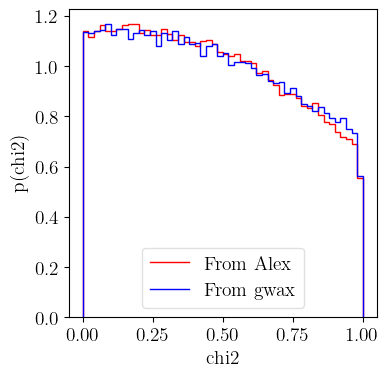

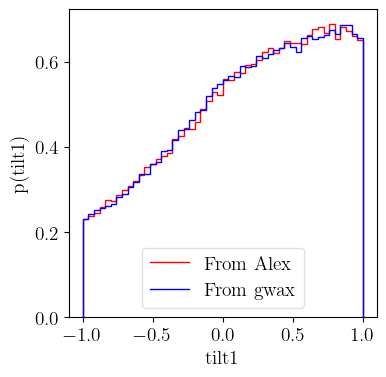

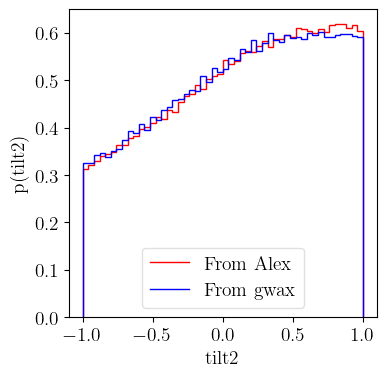

In [10]:
nbins=50

for k,key in enumerate(parameter_keys_0):
    
    fig, ax = plt.subplots(1, 1, figsize=(4,4))

    hist0, bins0 = np.histogram(observed_events_0[:,k], bins=nbins, density=True)
    hist1, bins1 = np.histogram(observed_events_1[:,k], bins=nbins, density=True)
    
    ax.stairs(hist0, bins0, color='r', label='From Alex')
    ax.stairs(hist1, bins1, color='blue', label='From gwax')
    
    ax.set_xlabel(key)
    ax.set_ylabel(f"p({key})")
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
    
    plt.show()

## Look at prior distributions

In [11]:
prior_first_event_0 = event_priors_0[:num_samples_0]
prior_first_event_1 = event_priors_1[:num_samples_1]

In [12]:
prior_first_event_0

array([0.00436095, 0.00246551, 0.00200169, ..., 0.00429502, 0.0036599 ,
       0.00249586], shape=(4278,))

In [13]:
prior_first_event_1

array([4.38544225e+08, 1.22925902e+09, 6.17518936e+08, ...,
       9.88556221e+08, 6.52991854e+08, 1.31305392e+09], shape=(3194,))

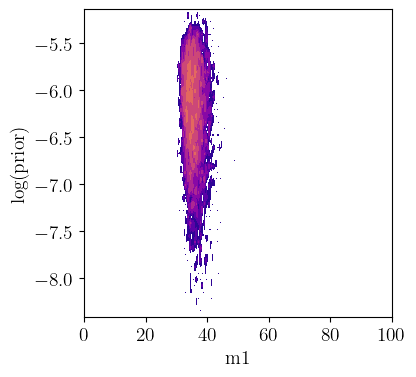

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(first_event_0[:,0], np.log(prior_first_event_0), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('m1')
ax.set_xlim(0,100)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

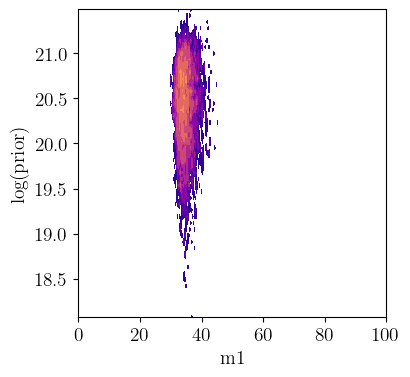

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(first_event_1[:,0], np.log(prior_first_event_1), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('m1')
ax.set_xlim(0,100)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

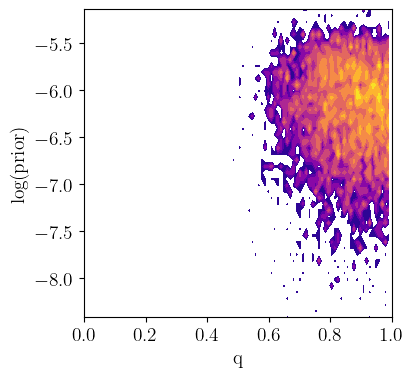

In [16]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(first_event_0[:,2], np.log(prior_first_event_0), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('q')
ax.set_xlim(0,1)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

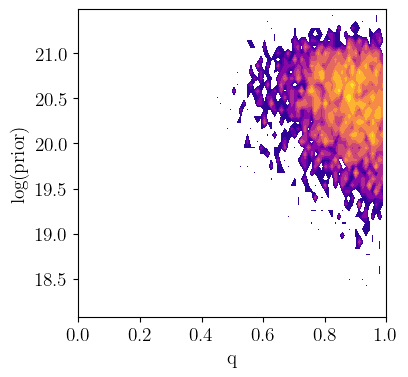

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(first_event_1[:,2], np.log(prior_first_event_1), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('q')
ax.set_xlim(0,1)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

# Injections

In [18]:
injections_file = np.load("./alex_samples/selection_function_elements.npz")
detected_injections_0 = np.vstack(
    [injections_file[key + "s"] for key in parameter_keys_0]
).T
injection_priors_0 = injections_file["inj_priors"]
num_injections_0 = int(injections_file["ninjs"][0])

In [19]:
print('Total number of injections for GWTC-3: %.2e' %num_injections_0)
print('Number of detected injections for GWTC-3: %.2e' %detected_injections_0.shape[0])

Total number of injections for GWTC-3: 7.33e+07
Number of detected injections for GWTC-3: 4.10e+04


In [20]:
injections_file = np.load("./gwax_samples/gwtc3_injections_full.npz")
detected_injections_1 = np.vstack(
    [injections_file[key + "s"] for key in parameter_keys_1]
).T
injection_priors_1 = injections_file["inj_priors"]
num_injections_1 = int(injections_file["ninjs"])

In [21]:
print('Total number of injections for GWTC-3: %.2e' %num_injections_1)
print('Number of detected injections for GWTC-3: %.2e' %detected_injections_1.shape[0])

Total number of injections for GWTC-3: 6.98e+08
Number of detected injections for GWTC-3: 5.91e+05


## Look at posterior distributions

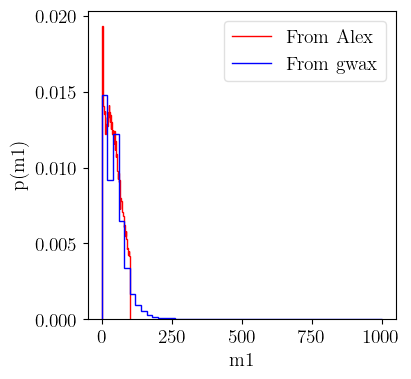

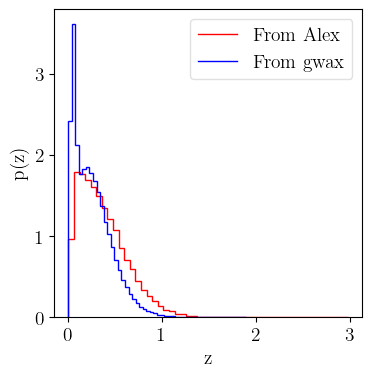

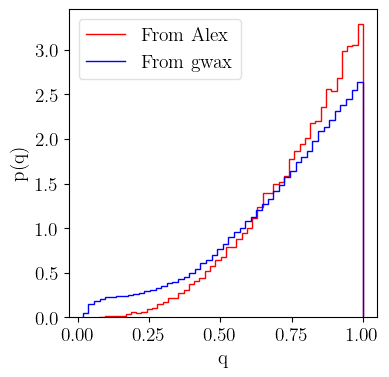

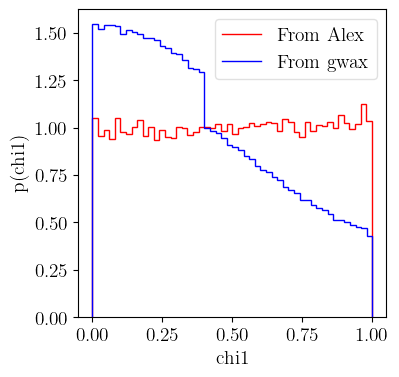

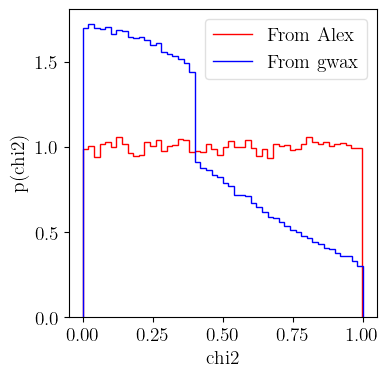

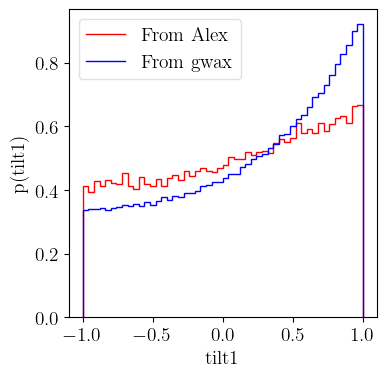

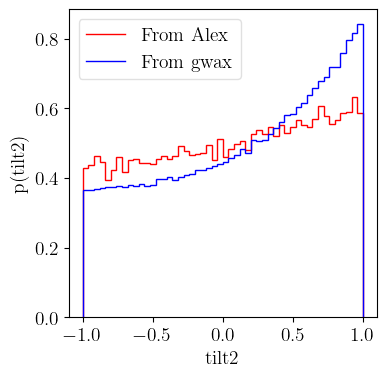

In [22]:
nbins=50

for k,key in enumerate(parameter_keys_0):
    
    fig, ax = plt.subplots(1, 1, figsize=(4,4))

    hist0, bins0 = np.histogram(detected_injections_0[:,k], bins=nbins, density=True)
    hist1, bins1 = np.histogram(detected_injections_1[:,k], bins=nbins, density=True)
    
    ax.stairs(hist0, bins0, color='r', label='From Alex')
    ax.stairs(hist1, bins1, color='blue', label='From gwax')
    
    ax.set_xlabel(key)
    ax.set_ylabel(f"p({key})")
    ax.legend(loc='best', framealpha=0.6)
    ax.set_box_aspect(1)
    
    plt.show()

## Look at prior distributions

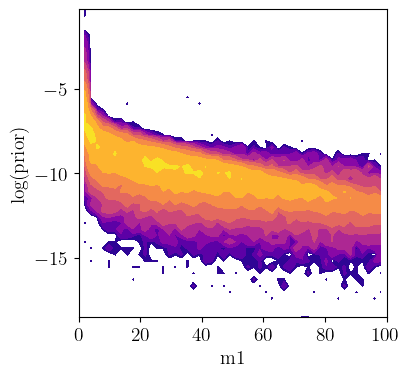

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(detected_injections_0[:,0], np.log(injection_priors_0), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('m1')
ax.set_xlim(0,100)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

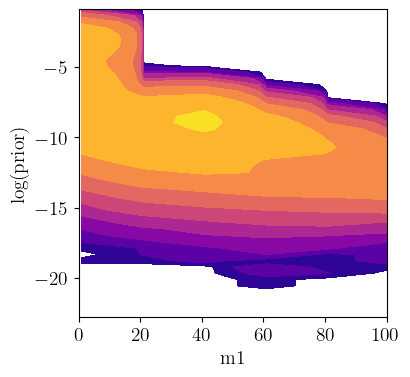

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(detected_injections_1[:,0], np.log(injection_priors_1), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('m1')
ax.set_xlim(0,100)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

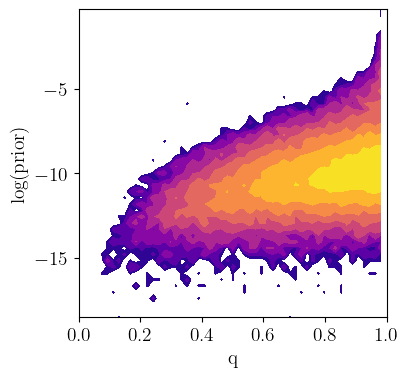

In [25]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(detected_injections_0[:,2], np.log(injection_priors_0), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('q')
ax.set_xlim(0,1)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()

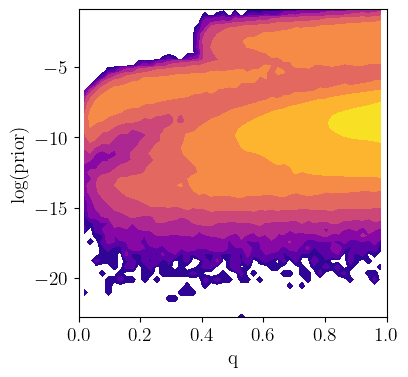

In [26]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

H, binsx0, binsy0 = np.histogram2d(detected_injections_1[:,2], np.log(injection_priors_1), bins=nbins, density=True)

X, Y = np.meshgrid(binsx0[:-1], binsy0[:-1])
Hmin=H[H>0].min()
Hmax=H[H>0].max()
vmin = int(Hmin /10**int(np.log10(Hmin)-1))*10**(int(np.log10(Hmin))-1)
vmax = int(Hmax /10**int(np.log10(Hmax))+1)*10**int(np.log10(Hmax))
H[H==0] = 1e-32
cmap = plt.get_cmap('plasma')
norm = mpl.colors.LogNorm(vmin=vmin, vmax=vmax)
im = ax.contourf(X, Y, H.T,
                 levels=np.logspace(np.log10(vmin),np.log10(vmax),10),
                 cmap=cmap,
                 norm=norm,
                )

ax.set_xlabel('q')
ax.set_xlim(0,1)
ax.set_ylabel('log(prior)')
ax.set_box_aspect(1)

plt.show()